# Lab 05 · A batch we can restart and explain

Automated Workflows in Satellite Image Processing · 5 November 2026

Lab 4 gave us one configured NDVI job. Lecture 5 asked whether its results were available, useful and explainable. Now we will run six requests and see what happens when one of them cannot finish.

By the end, you should be able to point to the expected work, explain an incomplete batch, recover it without losing history, and produce a report that another person can investigate.

The main exercise uses actual Sentinel-2 Collection 1 subsets from three dates near Kraków. Each date supplies two AOIs. The preserved inputs stay unchanged. Cloud screening comes later.

Core work: three new database tables, three logical repairs, two failure investigations, and a short decision. Allow about two hours. Coordinator interruption, missing outputs and the live acquisition route are extensions.

## 1. Open the package and inspect the evidence

Run the notebook from the Lab05 directory. Keep the supplied Python files beside it.

In [1]:
from pathlib import Path
import json, sqlite3, subprocess, sys
import numpy as np
import rasterio
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
assert (ROOT / 'lab05_cli.py').is_file(), 'Open the notebook from the extracted package directory.'

def cli(*args, expected=(0,)):
    child = subprocess.run([sys.executable, str(ROOT / 'lab05_cli.py'), *map(str, args)], capture_output=True, text=True)
    assert child.returncode in expected, (child.returncode, child.stdout[-2500:], child.stderr[-2500:])
    if child.returncode == 87:
        return {'exit_code': 87, 'note': 'The isolated coordinator stopped abruptly.'}
    return json.loads(child.stdout)

def check(group='all'):
    child = subprocess.run([sys.executable, str(ROOT / 'check_lab05.py'), group], capture_output=True, text=True)
    print(child.stdout)
    return child.returncode == 0

def query(manifest_path, sql, params=()):
    import batch_plan
    manifest = batch_plan.load(manifest_path)
    with sqlite3.connect(manifest['_database']) as connection:
        connection.row_factory = sqlite3.Row
        connection.execute('PRAGMA foreign_keys=ON')
        return [dict(row) for row in connection.execute(sql, params)]

print('Python', sys.version.split()[0], 'Rasterio', rasterio.__version__)
fixture = json.loads((ROOT / 'fixtures/manifest.json').read_text())
print('Endpoint:', fixture['endpoint'], 'Collection:', fixture['collection'])
print('Requests:', len(fixture['members']))

Python 3.14.0 Rasterio 1.5.0
Endpoint: https://earth-search.aws.element84.com/v1 Collection: sentinel-2-c1-l2a
Requests: 6


In [2]:
first_member = fixture['members'][0]
for role, entry in first_member['bands'].items():
    with rasterio.open(ROOT / 'fixtures' / entry['file']) as source:
        raw = source.read(1, masked=True)
        print(role, first_member['member_id'], source.shape, source.crs, source.scales, source.offsets, entry['sha256'])
        print('DN median:', float(np.ma.median(raw)))
print('Source transfer bytes:', sum(t['network_bytes'] for t in fixture['transfers']))

red S2A_T34UDA_20250604T094637_L2A-river (227, 219) EPSG:32634 (0.0001,) (-0.1,) ef3ca867df64c8b756ddd817d1ec25c6722f6e88a734863a63a95a9986abf684
DN median: 1778.0
nir S2A_T34UDA_20250604T094637_L2A-river (227, 219) EPSG:32634 (0.0001,) (-0.1,) e30bbf323834e7602031458e2b00f3d4b5e2ac06cd22a7967acf2032c78ec25c
DN median: 3441.0
Source transfer bytes: 12582918


**Name one property a checksum establishes and one scientific question it cannot answer.**

The SHA256 tells me the bytes I'm reading are exactly the bytes that were captured. For the river red subset and the pipeline rechecks it before every use, so a silent edit or a truncated copy can't sneak in. What it can't tell me is whether those pixels are any good. A cloudy, hazy or shadowed scene hashes just as cleanly as a clear one, and the checksum says nothing about whether the scale/offset (0.0001 / −0.1 here) was the right calibration to apply.

**Explain why six requests here represent three dates rather than six independent acquisitions.**

There are only three Sentinel-2 overpasses (S2A on 4 June, S2C on 5 June, S2B on 10 June 2025), and each one is cut into two small AOIs, `river` and `east`, that sit right next to each other. Both AOIs from the same date come from the same tile, the same metadata record (same `metadata_sha256`), the same sensor pass and the same atmosphere. If there's haze or a calibration problem on 4 June, both of that day's requests share it. So it's six processing requests but really three observations of the ground, and their errors are correlated, not independent.

## 2. Design the new tables

Read `SCHEMA_CONTRACT.md`. Write all three tables in `student_batch_schema.sql`. The earlier acquisition and processing schemas are completed in `support/`.

Before writing SQL, sketch the links between a batch, its expected members, their requests, attempts and observations. Decide which records must exist when we know what we want but no calculation has started.

**A member's planned request ID exists before its optional request foreign key can be filled. Explain why those are separate fields. Then run the schema check.**

In [3]:
schema_ok = check('schema')

[
  {
    "check": "schema",
    "passed": true
  }
]



Your explanation:

**A member's planned request ID exists before its optional request foreign key can be filled. Explain why those are separate fields.**

`planned_request_id` is the fingerprint of the frozen scientific spec. It can be computed the moment the manifest is frozen, before any `processing_requests` row exists. `request_id` is the real foreign key, and the coordinator only fills it once it has registered that request in the catalogue. If I merged the two, I'd have a choice between dropping the foreign key (and losing the guarantee that a registered request actually exists) or not being able to insert expected work until processing had started, which defeats the point of recording expected work. The `CHECK(request_id IS NULL OR request_id = planned_request_id)` keeps them honest; once the link appears, it has to point at the request that was planned.

**Decide which records must exist when we know what we want but no calculation has started.**

One `batches` row (frozen membership and budget) and one `batch_members` row per expected request, with `request_id` still NULL. No attempts and no observations are needed yet, and `plan` deliberately writes nothing. That's exactly what I got after setup: six members, all with `request_id = None`. The schema check passed.

## 3. Repair the coordination logic

The functions in `batch_repairs.py` execute, but the supplied versions make incorrect decisions. Read their contracts and repair them.

`classify_member` needs to distinguish blocked inputs, unresolved execution, verified completion and a permitted new attempt. A finished result may remain usable after its inputs move. An unresolved active execution needs attention even when an older result exists. The attempt budget does not reset when the coordinator restarts.

`verify_result` must reject evidence for another request, mismatching bytes, or missing verification. The adapter does the actual catalogue queries, hashing and raster inspection.

`summarize_batch` must count expected members once each using their newest observations. Repeated observations and joined locations do not create more requested work. Keep members that have no observation yet.

**Predict which check will expose each supplied defect before editing.**

In [4]:
for group in ('classify', 'verify', 'summary'):
    check(group)

[
  {
    "check": "classify",
    "passed": true
  }
]



[
  {
    "check": "verify",
    "passed": true
  }
]



[
  {
    "check": "summary",
    "passed": true
  }
]



Your explanation:

**Predict which check will expose each supplied defect before editing.**

Reading `check_lab05.py`, I expected `classify` to trip on the missing-input case, because the old code called it `failed`, but a missing file is something to go and look at, not a scientific failure, and it shouldn't burn budget. The old ordering had other problems too: it tested the budget and missing inputs before the verified result, so a finished product whose inputs had moved later would be marked failed. It also ignored `validation_error` and `last_attempt`, so an ordinary failed attempt would just be retried blindly. For `verify`, the only thing checked was a non-empty `artifact_id`, so I expected the first case (evidence for a different request) to be accepted. For `summary`, the old loop counted every joined row and skipped NULLs, so repeated rows would inflate counts and the never-observed member would vanish.

I ran the original functions (from git) against the checks to confirm. `classify` failed on `missing_inputs → blocked`, `verify` failed on `request_id`, and `summary` reported `expected: 4` with `one` counted as complete twice and also as failed. After the repairs all four groups pass. In `classify_member` the order is now: active attempt, then verified result, then validation, then missing inputs, then budget, then previous failure. A reconciled interruption may retry within budget.

## 4. Register expected work and run the batch

Finish the schema and function repairs before creating processing evidence. The next cell imports the captured real inputs into a fresh catalogue and freezes membership. It does not make a processing attempt.

Rerunning the notebook keeps existing work. To begin a separate experiment, choose a new workspace name.

In [5]:
assert check('all'), 'Finish the schema and three logical repairs first.'
MANIFEST = ROOT / 'work/batch.json'
if not MANIFEST.exists():
    print(cli('setup', '--directory', ROOT / 'work'))

expected_before = query(MANIFEST, 'SELECT member_id, planned_request_id, request_id FROM batch_members ORDER BY member_id')
expected_before

[
  {
    "check": "schema",
    "passed": true
  },
  {
    "check": "classify",
    "passed": true
  },
  {
    "check": "verify",
    "passed": true
  },
  {
    "check": "summary",
    "passed": true
  }
]



{'manifest': 'C:\\Automated_Workflows\\Labs\\Lab05\\work\\batch.json', 'database': 'C:\\Automated_Workflows\\Labs\\Lab05\\work\\catalogue.sqlite', 'members': 6, 'source': 'Captured real Collection 1 AOI subsets; no live request'}


[{'member_id': 'S2A_T34UDA_20250604T094637_L2A-east',
  'planned_request_id': 'request-becfe8dc2ddf75e39fdd9b982bde3c36db9a74a273a9c2fc83c0d4a8f4cb76c0',
  'request_id': None},
 {'member_id': 'S2A_T34UDA_20250604T094637_L2A-river',
  'planned_request_id': 'request-8a59b1684701905b091e6e9e63e93c4ff69fc5e4f262ff802f38b9e5a15fad7c',
  'request_id': None},
 {'member_id': 'S2B_T34UDA_20250610T095316_L2A-east',
  'planned_request_id': 'request-3685c0d16dc07369ebf9340f5a7125b5974253df63556241ad8139bcd9f8e220',
  'request_id': None},
 {'member_id': 'S2B_T34UDA_20250610T095316_L2A-river',
  'planned_request_id': 'request-04bda1299e436fe2479f2a07593a7abcbeed495633f51a1a700b47f78d140e79',
  'request_id': None},
 {'member_id': 'S2C_T34UDA_20250605T095638_L2A-east',
  'planned_request_id': 'request-587d694913bde7308badbcae109b4b78192b0dade7b1603f78c5b78b3aab7328',
  'request_id': None},
 {'member_id': 'S2C_T34UDA_20250605T095638_L2A-river',
  'planned_request_id': 'request-ac1e2ebd4597259a8e06a91db

Write a query that lists expected members with no application attempt. Run it now. It should include the whole batch. Keep the query, its parameters and your interpretation in `investigation_queries.sql`.

In [6]:
# Expected members that never reached an application attempt (reused rows do not count).
no_attempt_sql = """
SELECT m.member_id, m.planned_request_id, m.request_id
FROM batch_members m
WHERE m.batch_id = :batch_id
  AND NOT EXISTS (SELECT 1 FROM processing_attempts a
                  WHERE a.request_id = m.planned_request_id AND a.status <> 'reused')
ORDER BY m.member_id"""
BATCH_ID = query(MANIFEST, 'SELECT batch_id FROM batches')[0]['batch_id']
no_attempt = query(MANIFEST, no_attempt_sql, {'batch_id': BATCH_ID})
print(len(no_attempt), 'of', len(expected_before), 'expected members have no attempt yet')
no_attempt

6 of 6 expected members have no attempt yet


[{'member_id': 'S2A_T34UDA_20250604T094637_L2A-east',
  'planned_request_id': 'request-becfe8dc2ddf75e39fdd9b982bde3c36db9a74a273a9c2fc83c0d4a8f4cb76c0',
  'request_id': None},
 {'member_id': 'S2A_T34UDA_20250604T094637_L2A-river',
  'planned_request_id': 'request-8a59b1684701905b091e6e9e63e93c4ff69fc5e4f262ff802f38b9e5a15fad7c',
  'request_id': None},
 {'member_id': 'S2B_T34UDA_20250610T095316_L2A-east',
  'planned_request_id': 'request-3685c0d16dc07369ebf9340f5a7125b5974253df63556241ad8139bcd9f8e220',
  'request_id': None},
 {'member_id': 'S2B_T34UDA_20250610T095316_L2A-river',
  'planned_request_id': 'request-04bda1299e436fe2479f2a07593a7abcbeed495633f51a1a700b47f78d140e79',
  'request_id': None},
 {'member_id': 'S2C_T34UDA_20250605T095638_L2A-east',
  'planned_request_id': 'request-587d694913bde7308badbcae109b4b78192b0dade7b1603f78c5b78b3aab7328',
  'request_id': None},
 {'member_id': 'S2C_T34UDA_20250605T095638_L2A-river',
  'planned_request_id': 'request-ac1e2ebd4597259a8e06a91db

In [7]:
plan = cli('plan', '--manifest', MANIFEST)
print('Writes the database:', plan['writes_database'])
print([(m['member_id'], m['state'], m['reason']) for m in plan['members']])
result = cli('run', '--manifest', MANIFEST)
print('Complete:', result['complete'], 'New invocations:', len(result['invocations']))

Writes the database: False
[('S2A_T34UDA_20250604T094637_L2A-river', 'ready', 'Inputs verified; 2 attempt(s) left in budget'), ('S2A_T34UDA_20250604T094637_L2A-east', 'ready', 'Inputs verified; 2 attempt(s) left in budget'), ('S2C_T34UDA_20250605T095638_L2A-river', 'ready', 'Inputs verified; 2 attempt(s) left in budget'), ('S2C_T34UDA_20250605T095638_L2A-east', 'ready', 'Inputs verified; 2 attempt(s) left in budget'), ('S2B_T34UDA_20250610T095316_L2A-river', 'ready', 'Inputs verified; 2 attempt(s) left in budget'), ('S2B_T34UDA_20250610T095316_L2A-east', 'ready', 'Inputs verified; 2 attempt(s) left in budget')]


Complete: True New invocations: 6


**Predict what a second invocation will change. Will it create another scientific product, another application attempt, or only new batch observations?**

In [8]:
attempts_before = query(MANIFEST, 'SELECT COUNT(*) AS n FROM processing_attempts')[0]['n']
repeat = cli('run', '--manifest', MANIFEST)
attempts_after = query(MANIFEST, 'SELECT COUNT(*) AS n FROM processing_attempts')[0]['n']
print('New invocations:', len(repeat['invocations']))
assert repeat['complete'] and not repeat['invocations']
assert attempts_before == attempts_after

New invocations: 0


**Predict what a second invocation will change. Will it create another scientific product, another application attempt, or only new batch observations?**

Only new observations. The coordinator re-inspects each member, finds a succeeded attempt, rehashes the output and reopens the raster to check grid and tags, then appends a fresh `complete` observation. Nothing is launched. That's what happened: 0 new invocations and the same number of rows in `processing_attempts` before and after. The extra observations are useful in their own right, because they record that the outputs were still verified at a later time.

## 5. Look at the results and their report

A contact sheet makes the six results easy to compare. The saved raster values are not clipped. The display uses a fixed interval; blue and magenta identify values outside it.

Export a report, then open its HTML file. Follow one count to its members and inspect a request, producing attempt and verification time. Scientific cloud suitability should remain unassessed.

{'report': 'C:\\Automated_Workflows\\Labs\\Lab05\\reports\\main\\index.html', 'json': 'C:\\Automated_Workflows\\Labs\\Lab05\\reports\\main\\report.json', 'expected': 6, 'counts': {'ready': 0, 'complete': 6, 'blocked': 0, 'unresolved': 0, 'failed': 0, 'unobserved': 0}, 'members': {'ready': [], 'complete': ['S2A_T34UDA_20250604T094637_L2A-east', 'S2A_T34UDA_20250604T094637_L2A-river', 'S2B_T34UDA_20250610T095316_L2A-east', 'S2B_T34UDA_20250610T095316_L2A-river', 'S2C_T34UDA_20250605T095638_L2A-east', 'S2C_T34UDA_20250605T095638_L2A-river'], 'blocked': [], 'unresolved': [], 'failed': [], 'unobserved': []}}
{'expected': 6, 'counts': {'ready': 0, 'complete': 6, 'blocked': 0, 'unresolved': 0, 'failed': 0, 'unobserved': 0}, 'members': {'ready': [], 'complete': ['S2A_T34UDA_20250604T094637_L2A-east', 'S2A_T34UDA_20250604T094637_L2A-river', 'S2B_T34UDA_20250610T095316_L2A-east', 'S2B_T34UDA_20250610T095316_L2A-river', 'S2C_T34UDA_20250605T095638_L2A-east', 'S2C_T34UDA_20250605T095638_L2A-river'

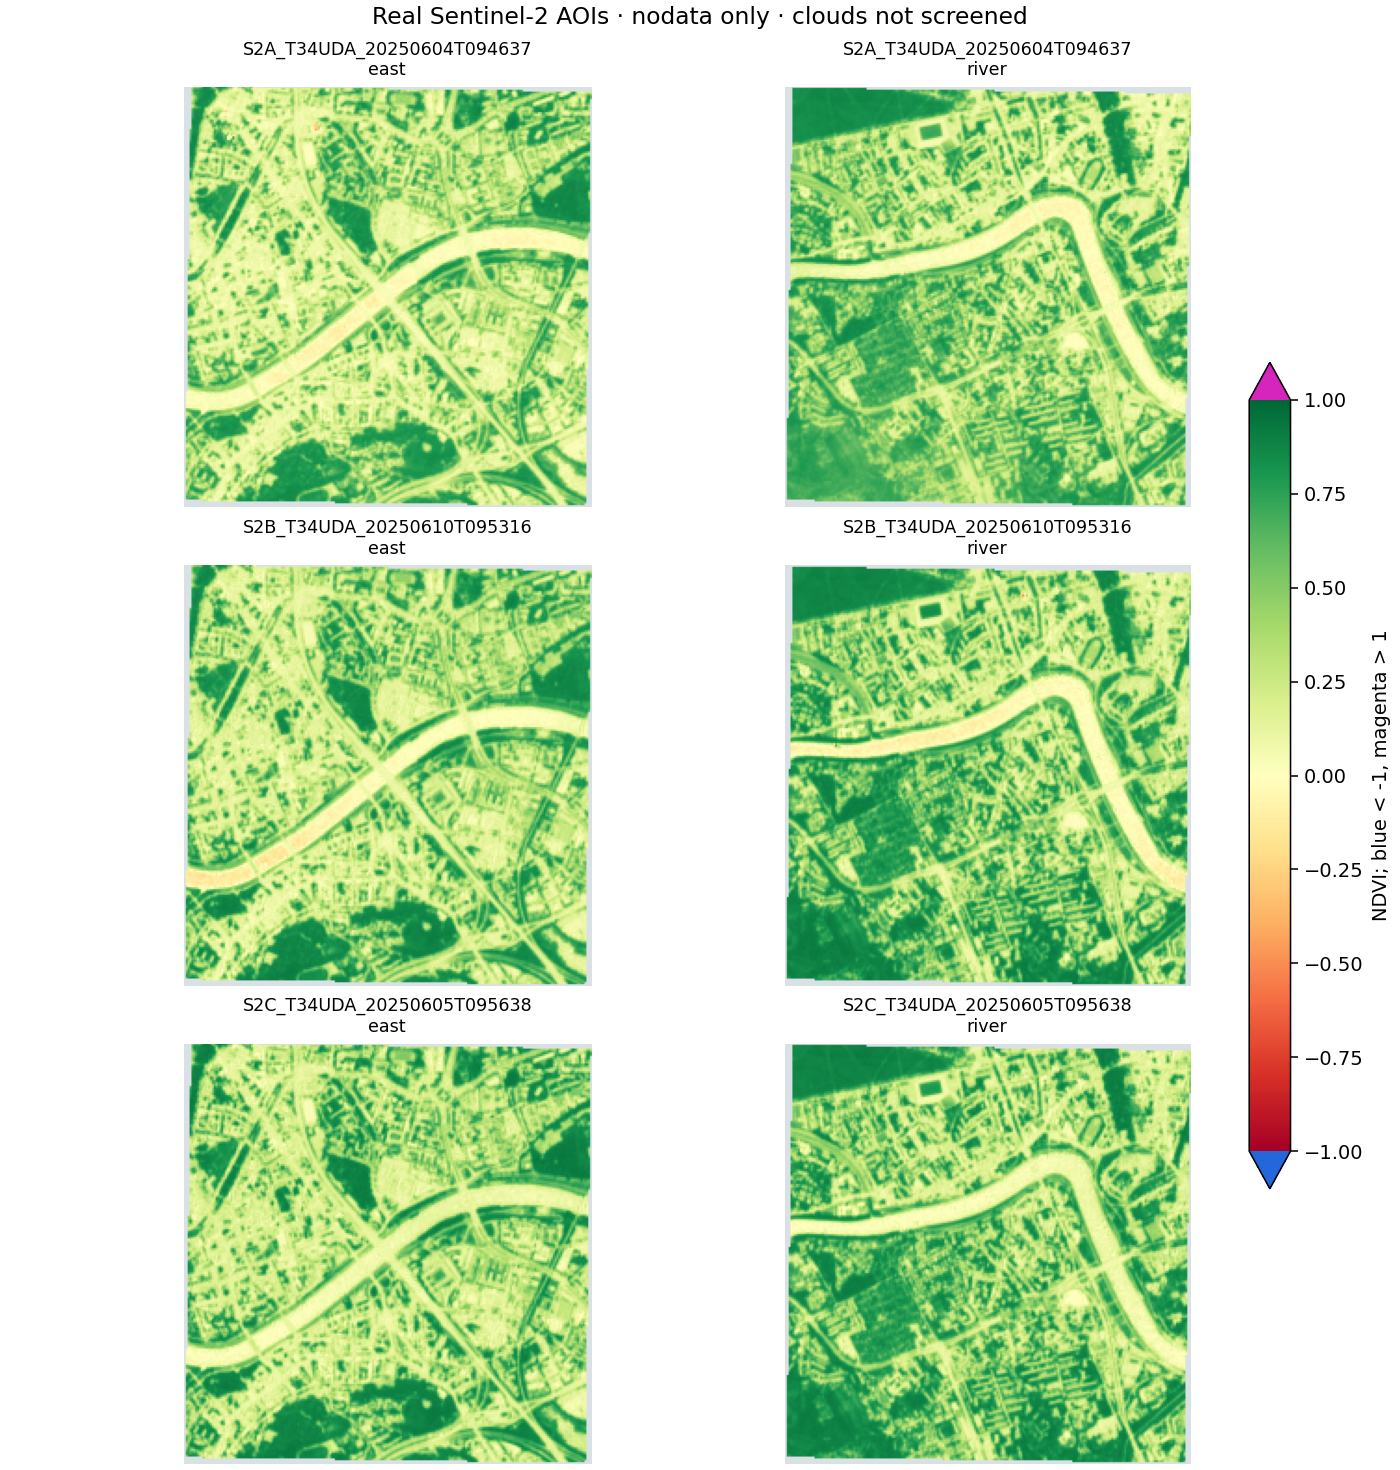

Open: C:\Automated_Workflows\Labs\Lab05\reports\main\index.html


In [9]:
report_dir = ROOT / 'reports/main'
if not report_dir.exists():
    print(cli('report', '--manifest', MANIFEST, '--output', report_dir))
report = json.loads((report_dir / 'report.json').read_text())
print(report['summary'])
from IPython.display import Image, display
if (report_dir / 'preview.png').is_file():
    display(Image(filename=str(report_dir / 'preview.png')))
print('Open:', report_dir / 'index.html')

**If the report says complete, what has it established? Give two reasons that still would not justify calling the image a clear sky vegetation observation. Identify the observation times separately from the report generation time.**

**If the report says complete, what has it established?**

For each of the six members there is a succeeded attempt whose output file was found on disk at observation time. Its size and SHA256 matched the catalogue, its grid matched the inputs (EPSG:32634, 10 m), and its tags point back to the right request and attempt. The validation also shows 96.1%–96.5% finite pixels and zero values outside [−1, 1] span. So the products exist, are intact and traceable.

**Give two reasons that still would not justify calling the image a clear sky vegetation observation.**

First, nothing looked at clouds. The mask policy is `nodata_only` and the report states `cloud_suitability: unassessed`. Thin cloud, haze or cloud shadow still produce perfectly finite NDVI values, just wrong ones, so "finite" is not "clear". Second, a valid NDVI number doesn't make the pixel vegetation. The river AOI contains water and built-up areas. Pixel values only tell me the arithmetic worked on L2A reflectance; they don't say the atmospheric correction was good on that day. The contact sheet is a visual check, not a QC measurement.

**Identify the observation times separately from the report generation time.**

There are three different clocks here. The satellite acquisitions were on 4, 5 and 10 June 2025 (around 09:46–09:56 UTC, from the scene IDs). The processing attempts ran between 09:44:36.6Z and 09:44:40.6Z on 9 Nov 2026, and the `complete` observations were written at 09:44:41.50–41.55Z. The report was generated at 09:44:42.29Z, with the snapshot taken a millisecond later. The report only replays those recorded observations. It did not recheck the files itself.

## 6. Case A · One input disappears

The case helper creates a separate workspace, moves one red input aside, and runs the normal coordinator. Your main workspace and preserved fixtures stay intact.

Predict the expected member count, attempt count and number of completed requests. Then identify the exact blocked member and input role using SQL.

In [10]:
def ensure_case(name, directory, expected=(0, 1)):
    case_manifest = ROOT / directory / 'batch.json'
    if not case_manifest.exists():
        result = cli('case', '--name', name, '--directory', ROOT / directory, expected=expected)
        print('Created:', name, result.get('manifest', result.get('note')))
    return case_manifest

missing = ensure_case('missing-input', 'cases/missing')
query(missing, """SELECT m.member_id, o.state, o.reason, o.observed_at
FROM batch_members m JOIN batch_observations o USING(batch_id,member_id)
WHERE o.observation_id=(SELECT MAX(x.observation_id) FROM batch_observations x
WHERE x.batch_id=m.batch_id AND x.member_id=m.member_id)
ORDER BY m.member_id""")

Created: missing-input C:\Automated_Workflows\Labs\Lab05\cases\missing\batch.json


[{'member_id': 'S2A_T34UDA_20250604T094637_L2A-east',
  'state': 'complete',
  'reason': 'Verified output output-9da77a9ba379e76e525e98c2c8646dbf5fd977173c6793fe8526d171e3518610 (bytes, grid and request/attempt tags)',
  'observed_at': '2026-11-09T09:44:48.643574Z'},
 {'member_id': 'S2A_T34UDA_20250604T094637_L2A-river',
  'state': 'blocked',
  'reason': 'No available verified copy of input role(s): red',
  'observed_at': '2026-11-09T09:44:48.634721Z'},
 {'member_id': 'S2B_T34UDA_20250610T095316_L2A-east',
  'state': 'complete',
  'reason': 'Verified output output-7dec1634cd587ccf47101153c4b1dd14134ce609637a2f72df777b1262648560 (bytes, grid and request/attempt tags)',
  'observed_at': '2026-11-09T09:44:48.680176Z'},
 {'member_id': 'S2B_T34UDA_20250610T095316_L2A-river',
  'state': 'complete',
  'reason': 'Verified output output-7a413671febb31e1136e6ed26cf7df89637988c0968c9e90d07292dae9d3f700 (bytes, grid and request/attempt tags)',
  'observed_at': '2026-11-09T09:44:48.671443Z'},
 {'me

In [11]:
query(missing, """SELECT a.artifact_id, json_extract(a.lineage_json,'$.asset_key') AS role,
 l.status, l.local_path, l.checked_at
FROM processing_artifacts a JOIN processing_artifact_locations l USING(artifact_id)
WHERE a.source_artifact_id IS NOT NULL AND l.status <> 'available'""")

[{'artifact_id': 'input-331652850adaf4329993d875808c8f484f0193258669c91175a7e127aa51489c',
  'role': 'red',
  'status': 'missing',
  'local_path': 'C:\\Automated_Workflows\\Labs\\Lab05\\cases\\missing\\inputs\\S2A_T34UDA_20250604T094637_L2A-river-red.tif',
  'checked_at': '2026-11-09T09:44:48.631202Z'}]

**Explain why the blocked member has no failed application attempt. How does expected membership let us see work that never started? Add the query that established your diagnosis to your query file.**

**Explain why the blocked member has no failed application attempt.**

The coordinator checks every input location before launching anything. For `S2A_…_L2A-river`, the red input had no available copy, so the member was classified `blocked` and the worker was never started --> job that never ran can't fail. The attempt table shows: five `succeeded` rows and nothing for the river request, and its budget is still untouched at 0 of 2. The location row shows which input checked at 09:44:48.631Z: role `red`, status `missing`, at `cases/missing/inputs/S2A_T34UDA_20250604T094637_L2A-river-red.tif`.

**How does expected membership let us see work that never started?**

Because `batch_members` lists all six requests up front, independently of whether anything ran. My no-attempt query (query 1 in `investigation_queries.sql`) returns the river member, and the latest observations show it as `blocked` alongside five `complete`. If I only looked at `processing_attempts`, I'd see only successes and conclude everything was fine. After restoring the file, the next `run` launched just that one job and the case ended with six succeeded attempts and no rewritten history.

In [12]:
note = json.loads((missing.parent / 'case_note.json').read_text())
if Path(note['held']).exists() and not Path(note['original']).exists():
    print(cli('restore-input', '--manifest', missing))
recovered = cli('run', '--manifest', missing)
print('Complete after restoration:', recovered['complete'])
query(missing, 'SELECT status, COUNT(*) AS n FROM processing_attempts GROUP BY status')

{'status': 'restored', 'path': 'C:\\Automated_Workflows\\Labs\\Lab05\\cases\\missing\\inputs\\S2A_T34UDA_20250604T094637_L2A-river-red.tif'}


Complete after restoration: True


[{'status': 'succeeded', 'n': 6}]

## 7. Case B · The worker stops before publication

This helper waits for the actual child process to stop with exit code 86. The child wrote and validated a temporary raster, then exited without running cleanup. Its attempt still says running.

Predict what the coordinator will do with the remaining requests. We still permit only one active processing invocation per catalogue.

In [13]:
worker = ensure_case('interrupted-worker', 'cases/worker')
query(worker, 'SELECT attempt_id, request_id, status, stage, temp_path, final_path FROM processing_attempts ORDER BY started_at')

Created: interrupted-worker C:\Automated_Workflows\Labs\Lab05\cases\worker\batch.json


[{'attempt_id': 'attempt-26dd2c8d863e46a2a9802db3222e930f',
  'request_id': 'request-8a59b1684701905b091e6e9e63e93c4ff69fc5e4f262ff802f38b9e5a15fad7c',
  'status': 'running',
  'stage': 'before_rename',
  'temp_path': 'C:\\Automated_Workflows\\Labs\\Lab05\\cases\\worker\\outputs\\.attempt-26dd2c8d863e46a2a9802db3222e930f.partial.tif',
  'final_path': 'C:\\Automated_Workflows\\Labs\\Lab05\\cases\\worker\\outputs\\attempt-26dd2c8d863e46a2a9802db3222e930f.ndvi.tif'}]

**Use SQL and file inspection to distinguish an interrupted execution from a missing input. Record why it is justified to assert that this child stopped. In a real unattended system, a timestamp alone would not establish that.**

In [14]:
running = query(worker, "SELECT attempt_id, temp_path, final_path FROM processing_attempts WHERE status='running'")
for row in running:
    print(row['attempt_id'], 'temporary:', Path(row['temp_path']).exists(), 'final:', Path(row['final_path']).exists())
print('Output links:', query(worker, 'SELECT COUNT(*) AS n FROM processing_outputs'))

attempt-26dd2c8d863e46a2a9802db3222e930f temporary: True final: False
Output links: [{'n': 0}]


With a missing input, the member is `blocked`, there's no attempt row, and a location check says missing. Here it's the opposite -> inputs were fine, and there is an attempt with status `running` at stage `before_rename`. The temporary file exists, the final file doesn't, and `processing_outputs` has zero links. The attempt's log ends with a `before_rename` entry that includes the temp file's SHA256. So the worker computed and validated a raster but died before publishing it. The coordinator marked that member `unresolved` and the other five `blocked` ("Catalogue has an unresolved execution"), because only one active execution per catalogue is allowed.

**Record why it is justified to assert that this child stopped.**

The helper program launched the worker process as a child process and waited for it to finish. The process returned an exit code of 86  on this machine while the Lab05 lock was held. The parent process detected the process’s termination and terminated based on the old timestamp.

**In a real unattended system, a timestamp alone would not establish that.** --> 
A stale `started_at` could just as well be a slow job, a hung NFS write or a process running on another node. There you'd want the scheduler's job state or host check that has clearly stopped before reconciling, otherwise you risk two writers producing the same output.

In [15]:
for row in running:
    print(cli('reconcile', '--manifest', worker, '--attempt-id', row['attempt_id'], '--confirm-stopped'))
worker_recovered = cli('run', '--manifest', worker)
assert worker_recovered['complete']
query(worker, 'SELECT request_id, status, error_code, started_at FROM processing_attempts ORDER BY started_at')

{'status': 'interrupted', 'attempt_id': 'attempt-26dd2c8d863e46a2a9802db3222e930f', 'retry': 'same request, new attempt'}


[{'request_id': 'request-8a59b1684701905b091e6e9e63e93c4ff69fc5e4f262ff802f38b9e5a15fad7c',
  'status': 'interrupted',
  'error_code': 'PROCESS_STOPPED_BEFORE_PUBLISH',
  'started_at': '2026-11-09T09:44:52.330415Z'},
 {'request_id': 'request-8a59b1684701905b091e6e9e63e93c4ff69fc5e4f262ff802f38b9e5a15fad7c',
  'status': 'succeeded',
  'error_code': None,
  'started_at': '2026-11-09T09:44:54.580372Z'},
 {'request_id': 'request-becfe8dc2ddf75e39fdd9b982bde3c36db9a74a273a9c2fc83c0d4a8f4cb76c0',
  'status': 'succeeded',
  'error_code': None,
  'started_at': '2026-11-09T09:44:55.342967Z'},
 {'request_id': 'request-ac1e2ebd4597259a8e06a91db6eb19eb75f176823d990469ca83046e51af9892',
  'status': 'succeeded',
  'error_code': None,
  'started_at': '2026-11-09T09:44:56.113335Z'},
 {'request_id': 'request-587d694913bde7308badbcae109b4b78192b0dade7b1603f78c5b78b3aab7328',
  'status': 'succeeded',
  'error_code': None,
  'started_at': '2026-11-09T09:44:56.965996Z'},
 {'request_id': 'request-04bda1299e

Write a query that finds a request with an interrupted or failed attempt and a later producing attempt. Show both identities. Explain why counting attempts would overstate delivered work.

In [16]:
# Recovery query: a request whose attempt failed or was interrupted and that later
# produced an output the batch observed as complete. Both attempt identities are shown.
recovery_sql = """
SELECT bad.request_id,
       bad.attempt_id   AS problem_attempt, bad.status AS problem_status,
       bad.error_code,  bad.started_at AS problem_started,
       good.attempt_id  AS producing_attempt, good.started_at AS produced_started,
       o.artifact_id    AS output_artifact
FROM processing_attempts bad
JOIN processing_attempts good
  ON good.request_id = bad.request_id AND good.status = 'succeeded'
 AND good.started_at > bad.started_at
JOIN processing_outputs o ON o.attempt_id = good.attempt_id AND o.role = 'ndvi'
WHERE bad.status IN ('failed', 'interrupted')
  AND EXISTS (SELECT 1 FROM batch_observations bo
              WHERE bo.attempt_id = good.attempt_id AND bo.state = 'complete')
ORDER BY bad.started_at"""
recovery = query(worker, recovery_sql)
attempt_count = query(worker, "SELECT COUNT(*) AS attempts, COUNT(DISTINCT request_id) AS requests FROM processing_attempts WHERE status <> 'reused'")[0]
print(attempt_count)
recovery

{'attempts': 7, 'requests': 6}


[{'request_id': 'request-8a59b1684701905b091e6e9e63e93c4ff69fc5e4f262ff802f38b9e5a15fad7c',
  'problem_attempt': 'attempt-26dd2c8d863e46a2a9802db3222e930f',
  'problem_status': 'interrupted',
  'error_code': 'PROCESS_STOPPED_BEFORE_PUBLISH',
  'problem_started': '2026-11-09T09:44:52.330415Z',
  'producing_attempt': 'attempt-3f0f4fa089b14f8ab9e534dd0abd0a00',
  'produced_started': '2026-11-09T09:44:54.580372Z',
  'output_artifact': 'output-2392797f8be164b9caa9864c7c015dc4a2ab814f6cbf52d5d4e2d70309a83f61'}]

The query above returns one row: request with interrupted attempt (`PROCESS_STOPPED_BEFORE_PUBLISH`), followed by producing attempt and its output artifact. It also requires a complete batch observation citing the producing attempt, so a succeeded status alone isn't treated as proof.

**Explain why counting attempts would overstate delivered work.**

If someone were to measure progress by the number of attempts, they would count 7 “completed tasks”, but only 6 requests and 6 products delivered, because one attempt came to nothing. This surplus isn’t an additional result - it’s a wasted effort that had to be repeated.


## 8. A decision another person can follow

It is Saturday morning. One member is blocked because an input file is missing. Five other members have verified outputs. Delivery is required on Monday afternoon.

Write a short note stating what is known, what remains uncertain, the next check, and whether you would act now or defer. Explain how your decision changes if an incorrect calibration may have affected already published products.

Save your useful SQL with a question, parameters, empty-result interpretation and next action. Sketch one overview and one detail view using the fields you actually have. Mark any proposed future measurements as unavailable rather than inventing them.

**What is known, what remains uncertain, the next check, and whether you would act now or defer.**

*Saturday, `batch-657ba611…`*: five of six members have verified outputs: bytes, grid and request/attempt tags all checked at their observation times. One member, `S2A_T34UDA_20250604T094637_L2A-river`, is blocked because its red input has no available copy. It has never had an attempt, so its full budget of two is still there. What I don't know yet is why the file disappeared (a move, a sync tool, or deletion) or whether the copy I'd restore is byte-identical to the registered one. Cloud suitability of all six is also still unassessed. The next check is to find the file and compare its SHA256 against the catalogue. If it matches, restore it and run the same manifest. That launches one job and leaves the five finished products alone.

I'd act now rather than wait for Monday. The fix is small and reversible, costs at most one attempt, and the five good products are protected because the coordinator re-verifies instead of recomputing. If the file can't be found, I'd deliver the five on Monday with the sixth clearly marked as blocked, rather than substituting anything.

**Explain how your decision changes if an incorrect calibration may have affected already published products.**

Theoretically, I would stop and not deliver on Monday by default. A calibration error doesn't show up in any of my checks: the hashes, grids and tags would all still pass, because the wrong numbers were written faithfully. The fix is a new manifest with the corrected scientific setting, which means new requests, so the old products stay in the catalogue as history rather than being overwritten. I'd also tell whoever already received outputs. That's a decision for the project lead, not something to push through on Saturday.

**Sketch one overview and one detail view using the fields you actually have.**

The overview is one row per expected member: `member_id`, latest `state`, `observed_at`, attempts used against `max_attempts`, and `valid_fraction`. It has a count strip with ready, complete, blocked, unresolved, failed and unobserved, where each count links to its members. The detail view, for one member, shows `planned_request_id` and `request_id`, the full attempt history (`attempt_id`, `status`, `error_code`, `started_at`/`finished_at`), the output `artifact_id` and its locations with `status` and `checked_at`, the input roles with their location checks, and the validation block (`crs`, `shape`, `mean`, `outside_nominal_range`, `mask_policy`). 

Cloud fraction, an SCL-based clear-sky percentage and the per-AOI land cover share are not measured in this lab, so they would appear as *unavailable*, not as numbers.

## Extensions

1. Create `interrupted-coordinator` in a new case directory. The command exits with code 87 after one completed member. Run the same manifest again and prove that only five jobs launch.
2. Create `missing-output`. Inspect both the old succeeded attempt and the new location observations. Recover the output without rewriting history.
3. Add a second copy of a verified output, then remove one copy. Explain why a query using any missing location gives the wrong answer.
4. Repeat the explicit live acquisition command from `README.md` into a new directory. Compare its captured source metadata and subset hashes with the supplied manifest.
5. Change a scientific setting in one configuration and freeze a new manifest. Contrast that new request with a change to an output directory.

Keep extensions separate from your core evidence. Never remove old attempt rows to make a report look clean.

### Extension results (run from the command line, kept separate from the core evidence)

**1. Interrupted coordinator.** `case --name interrupted-coordinator --directory cases/coordinator` exited with 87 after one product. At that point the catalogue held one succeeded attempt and two observations (one `ready`, one `complete`). Four members had no observation at all, which the summary reports as `unobserved`. Running the same manifest again launched exactly 5 jobs and ended with 6 succeeded attempts. The finished product was verified and kept, not recomputed.

**2. Missing output.** In `cases/output` the helper moved the river output aside, and `refresh` recorded its location as `missing`. The member's latest observation went from `complete` to `ready` ("1 attempt(s) left"), but the old attempt `attempt-620b861a…` still says `succeeded`. History isn't rewritten just because a file went missing. `run` launched one new attempt (`attempt-2e1a5724…`), which produced a new verified output, so the member is `complete` again with 2 of 2 attempts used.

**3. Two copies, one removed.** I copied the S2B east output to `cases/output/archive_copy/`, registered it as a second location, moved the original away, and ran `refresh`. A query that asks "does this product have any location not available" flagged S2B east as a problem. A query that asks "does it have no available location" (query 3 in `investigation_queries.sql`) correctly left it out. The member stayed `complete`, verified from the archive copy. One lost copy is not a lost product.

**4. Live acquisition.** Not run yet. It downloads about 12 MiB from Earth Search / AWS.

**5. Scientific change vs output directory.** From the S2B river config I froze two one-member manifests against the `cases/output` catalogue. Changing only `runtime.output_dir` produced the same `request-04bda129…` as the original. Its run launched 0 jobs, because the existing product was verified and reused. Changing `min_valid_fraction` from 0.1 to 0.5 produced a different request, `request-dff0ece3…`, and its run launched one new attempt. Storage location is bookkeeping, while a scientific setting is part of the request identity, so it needs a new manifest and its own budget.

## Submit

Keep your notebook, three table definitions, three repairs, query file, one saved report, and the decision note. Include the failed/interrupted evidence as well as the recovered outcome.

The extensions are optional.